# 02 — Pipeline de IA e placar

Rode **em ordem**, a partir da pasta `notebooks/`. Pré-requisito: o adaptador LoRA em `../modelo-lora-rag/` (gerado pelo notebook 01).


In [1]:
# Dependências (rode uma vez, no terminal ou aqui)
!pip install -r ../requirements.txt

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Base de conhecimento, gabarito e perguntas


In [2]:
import sys
!{sys.executable} ../src/gerar_dados.py

Base: 100 boletins (IDs únicos: 100)
Perguntas: 30 válidas + 20 fora de escopo
Exemplo: Aconteceu um sequestro na avenida paulista. O bandido tava com um pedaço de pau. tá morto. | Tem relato de agressão em praça da sé? Eles usaram uma faca. -> gold ['BO-9196']


## 2. Busca: recall@1, recall@3 e limiar (critério 03)


In [3]:
import sys
!{sys.executable} ../avaliacao/busca.py

## Busca semântica — recall e limiar

Base: 100 trechos | 30 perguntas válidas (com gabarito) + 20 fora de escopo (devem virar "não consta")

| Buscador | recall@1 | recall@3 | limiar escolhido | acurácia da decisão no limiar |
|---|---|---|---|---|
| all-MiniLM-L6-v2 | 90% | 100% | 0.7 | 94% |
| paraphrase-multilingual-MiniLM-L12-v2 | 73% | 93% | 0.67 | 82% |

**Escolhido:** `sentence-transformers/all-MiniLM-L6-v2` com limiar **0.7**.

### Justificativa do limiar

Decisão correta = (pergunta válida com score >= limiar **e** top-1 certo) ou (pergunta fora de escopo com score < limiar).

| limiar | 0.4 | 0.5 | 0.6 | 0.65 | 0.7 | 0.75 | 0.8 | 0.85 |
|---|---|---|---|---|---|---|---|---|
| acurácia | 54% | 64% | 84% | 90% | 94% | 88% | 78% | 54% |

Scores das perguntas válidas: min 0.71, mediana 0.82. Fora de escopo: mediana 0.54, máx 0.69. O limiar fica no platô [0.7, 0.7] de máxima acurácia; usamos o ponto central para ter margem dos dois lados.


W1112 20:20:01.347000 20776 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2432.49it/s]
C:\Users\Victor T\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Victor T\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, 

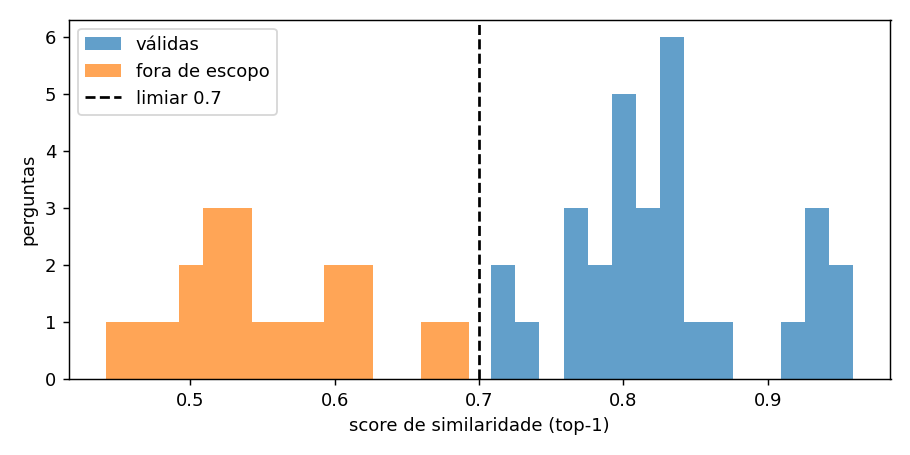

In [4]:
from IPython.display import Image
Image('../avaliacao/limiar.png')

## 3. Placar das 3 configurações (critérios 04, 05 e 06)

Demora alguns minutos (carrega o Qwen em 4 bits e roda 3 configurações).


In [5]:
import sys
!{sys.executable} ../avaliacao/placar.py

Buscador: sentence-transformers/all-MiniLM-L6-v2 | limiar 0.7
Config A pronta em 131s
Config B pronta em 198s
Config C pronta em 296s
## Placar das três configurações

Buscador `all-MiniLM-L6-v2`, limiar 0.7, geração greedy (determinística). 30 perguntas válidas + 20 fora de escopo.

### Ponta a ponta (pergunta → busca → geração)

| Métrica | A · Base sem contexto | B · Base + RAG simples | C · LoRA + RAG |
|---|---|---|---|
| Acerto total (resposta certa ou recusa certa) | 16/50 (32%) | 34/50 (68%) | 45/50 (90%) |
| JSON válido (schema) | 19/50 (38%) | 46/50 (92%) | 50/50 (100%) |
| Fonte correta (válidas) | 0/30 (0%) | 27/30 (90%) | 27/30 (90%) |
| Campos + fonte corretos (válidas) | 0/30 (0%) | 14/30 (47%) | 25/30 (83%) |
| Recusa correta (fora de escopo) | 16/20 (80%) | 20/20 (100%) | 20/20 (100%) |
| Alucinação (menor é melhor) | 31/50 (62%) | 14/50 (28%) | 3/50 (6%) |

### Extração isolada (30 casos com gabarito, 4 são "não consta")

| Métrica | B · Base + RAG simples | C · LoRA 

W1112 20:22:27.453000 12896 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2770.29it/s]

Loading weights: 100%|██████████| 434/434 [00:08<00:00, 53.97it/s]


## 4. Erros candidatos para o relatório (critério 07)


In [6]:
from IPython.display import Markdown
Markdown(open('../avaliacao/erros_candidatos.md', encoding='utf-8').read())

# Erros candidatos (gerado automaticamente)

## Config A: 34 erros — {'fonte inexistente (alucinação)': 27, 'recusa indevida (pergunta válida)': 3, 'não recusou fora de escopo': 4}

- **Q01** [fonte inexistente (alucinação)] pergunta: Tem relato de agressão em praça da sé? Eles usaram uma faca.
  resposta: `{"local": "praça da sé", "crime": "agressão", "arma": "faca", "tipo_arma": "lanceira", "estado_vitima": "nenhum informado", "fonte": "notícia"}`
- **Q07** [recusa indevida (pergunta válida)] pergunta: Houve algum caso de ameaça em rua de trás em que o criminoso estava com uma pistola?
  resposta: `{"resultado": "não consta"}`
- **Q35** [não recusou fora de escopo] pergunta: Briga de dinossauros T-Rex no museu de história natural.
  resposta: `{"local": "museu de história natural", "crime": "briga de dinossauros T-Rex", "arma": "nenhum informado", "tipo_arma": "nenhum informado", "estado_vitima": "nenhum informado", "fonte": "não consta"}`

## Config B: 16 erros — {'fonte errada (busca trouxe outro boletim)': 3, 'campo errado': 13}

- **Q03** [fonte errada (busca trouxe outro boletim)] pergunta: Tem relato de ameaça em ponto de ônibus? Eles usaram um facão.
  resposta: `{"local": "ponto de ônibus", "crime": "ameaça", "arma": true, "tipo_arma": "branca", "estado_vitima": "fatalidade", "fonte": "BO-7528"}`
- **Q06** [campo errado: crime,estado_vitima] pergunta: Preciso do boletim de homicídio ocorrido em rua de trás envolvendo um revólver.
  resposta: `{"local": "rua de trás", "crime": "homicidio", "arma": true, "tipo_arma": "fogo", "estado_vitima": "fatalidade", "fonte": "BO-9293"}`

## Config C: 5 erros — {'fonte errada (busca trouxe outro boletim)': 3, 'campo errado': 2}

- **Q03** [fonte errada (busca trouxe outro boletim)] pergunta: Tem relato de ameaça em ponto de ônibus? Eles usaram um facão.
  resposta: `{"local": "ponto de ônibus", "crime": "ameaça", "arma": true, "tipo_arma": "branca", "estado_vitima": "fatalidade", "fonte": "BO-7528"}`
- **Q28** [campo errado: arma,tipo_arma] pergunta: Vandalismo em estacionamento do shopping, o bandido tava com na mão grande.
  resposta: `{"local": "estacionamento do shopping", "crime": "vandalismo", "arma": true, "tipo_arma": "branca", "estado_vitima": "sem_lesao", "fonte": "BO-3753"}`
